# Lab 12 — Training an Imaging Model: From Scratch versus Transfer Learning
AI in Healthcare · Unit IV · B.Tech AI, Third Year


In [1]:
import hashlib
import os
import random
import time
import urllib.request
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ON_KAGGLE = Path("/kaggle/working").is_dir()
DATA_DIR = (Path("/kaggle/working") if ON_KAGGLE else Path.cwd()) / "lab12_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
os.environ["TORCH_HOME"] = str(DATA_DIR / "torch")   # pretrained weights are cached here

print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | scikit-learn {sklearn.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU found")
print("data directory:", DATA_DIR)
if DEVICE.type == "cpu":
    print("WARNING: running on CPU. Training will be slow; on Kaggle, switch the accelerator to GPU.")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)


def answer(text):
    display(Markdown(text))

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | scikit-learn 1.6.1
device: cuda | Tesla T4
data directory: /content/lab12_data


In [2]:
DATA_URL = "https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1"
DATA_MD5 = "8f4eceb4ccffa70c672198ea285246c6"   # published in the MedMNIST package metadata


def md5sum(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


attached = sorted(Path("/kaggle/input").glob("**/pneumoniamnist_64.npz")) if ON_KAGGLE else []
DATA_FILE = attached[0] if attached else DATA_DIR / "pneumoniamnist_64.npz"
if not DATA_FILE.exists():
    print("Downloading PneumoniaMNIST (64 x 64), about 21 MB ...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
if md5sum(DATA_FILE) != DATA_MD5:
    raise ValueError(f"{DATA_FILE} does not match the published checksum; delete it and rerun.")

data = np.load(DATA_FILE)
SPLITS = ("train", "val", "test")
IMAGES = {s: data[f"{s}_images"] for s in SPLITS}                     # uint8, shape (n, 64, 64)
LABELS = {s: data[f"{s}_labels"].ravel().astype(int) for s in SPLITS}  # 0 = normal, 1 = pneumonia
CLASS_NAMES = {0: "normal", 1: "pneumonia"}
print("loaded", DATA_FILE, "| MD5 verified")
for s in SPLITS:
    print(f"{s:5}  images {IMAGES[s].shape}  labels {LABELS[s].shape}")

loaded /content/lab12_data/pneumoniamnist_64.npz | MD5 verified
train  images (4708, 64, 64)  labels (4708,)
val    images (524, 64, 64)  labels (524,)
test   images (624, 64, 64)  labels (624,)


## Part 1 — Know the data before training
### Exercise 1.1 — Split summary

In [3]:
def split_summary():
    rows = []
    for s in SPLITS:
        y = LABELS[s]
        n = int(len(y))
        n_normal = int((y == 0).sum())
        n_pneu = int((y == 1).sum())
        rows.append({"split": s, "images": n, "normal": n_normal, "pneumonia": n_pneu,
                     "pneumonia_fraction": n_pneu / n})
    return pd.DataFrame(rows)


summary = split_summary()
display(summary)
check("train has 4,708 images", summary.get("images", pd.Series([None])).iloc[0] == 4708)
check("train has 3,494 pneumonia images", summary.get("pneumonia", pd.Series([None])).iloc[0] == 3494)

,split,images,normal,pneumonia,pneumonia_fraction
0,train,4708,1214,3494,0.742141
1,val,524,135,389,0.742366
2,test,624,234,390,0.625000


PASS  train has 4,708 images
PASS  train has 3,494 pneumonia images


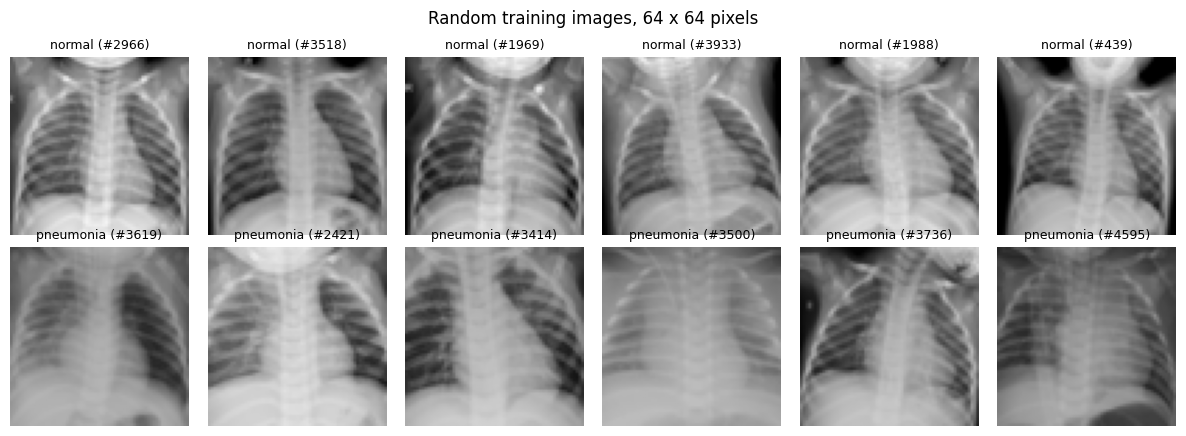

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
rng = np.random.default_rng(SEED)
for row, label in enumerate((0, 1)):
    idx = rng.choice(np.flatnonzero(LABELS["train"] == label), size=6, replace=False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(IMAGES["train"][i], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{CLASS_NAMES[label]} (#{i})", fontsize=9)
        ax.axis("off")
fig.suptitle("Random training images, 64 x 64 pixels")
plt.tight_layout()
plt.show()

### Exercise 1.2 — Interpret
✍️ Answer (generated from this run's numbers):

In [5]:
S = summary.set_index("split")
fr = {s: S.loc[s, "pneumonia_fraction"] for s in SPLITS}
answer(f"""**Exercise 1.2 — answer**

1. One row is one 64 × 64 greyscale chest X-ray with one label (normal or pneumonia): the unit of analysis is the **image**, not the patient. "4,708 training images" is not "4,708 children" because the files carry no patient identifiers and the source collection can contain several X-rays from the same child, so the number of distinct children is unknown and at most 4,708.
2. The val set was cut **randomly at image level** from the same pool as train. If one child contributes images to both, the model can recognise that child's anatomy or acquisition quirks rather than pneumonia (patient-level leakage), and train and val share one source population and one prevalence. Validation results are therefore optimistic compared with truly unseen patients.
3. The pneumonia fraction is {fr['val']:.1%} in val but {fr['test']:.1%} in test. **PPV** (and NPV, and accuracy) depend on prevalence, so they will change between val and test even if the model is identical; sensitivity and specificity, and AUROC, are in principle prevalence-independent.
4. No. This is an enriched research dataset ({fr['train']:.1%} pneumonia in training). A children's clinic would see a much lower pneumonia fraction among X-rays, so the same model would have a **lower PPV** (more false alarms per true case) and a higher NPV in practice than the dataset suggests; metrics that depend on prevalence cannot be transferred without recalculation.""")

**Exercise 1.2 — answer**

1. One row is one 64 × 64 greyscale chest X-ray with one label (normal or pneumonia): the unit of analysis is the **image**, not the patient. "4,708 training images" is not "4,708 children" because the files carry no patient identifiers and the source collection can contain several X-rays from the same child, so the number of distinct children is unknown and at most 4,708.
2. The val set was cut **randomly at image level** from the same pool as train. If one child contributes images to both, the model can recognise that child's anatomy or acquisition quirks rather than pneumonia (patient-level leakage), and train and val share one source population and one prevalence. Validation results are therefore optimistic compared with truly unseen patients.
3. The pneumonia fraction is 74.2% in val but 62.5% in test. **PPV** (and NPV, and accuracy) depend on prevalence, so they will change between val and test even if the model is identical; sensitivity and specificity, and AUROC, are in principle prevalence-independent.
4. No. This is an enriched research dataset (74.2% pneumonia in training). A children's clinic would see a much lower pneumonia fraction among X-rays, so the same model would have a **lower PPV** (more false alarms per true case) and a higher NPV in practice than the dataset suggests; metrics that depend on prevalence cannot be transferred without recalculation.

## Part 2 — Metrics and baselines
### Exercise 2.1 — Metrics at a threshold

In [6]:
def binary_metrics(y_true, p, threshold=0.5):
    y_true = np.asarray(y_true)
    y_hat = (np.asarray(p) >= threshold).astype(int)
    tp = int(((y_hat == 1) & (y_true == 1)).sum())
    fn = int(((y_hat == 0) & (y_true == 1)).sum())
    tn = int(((y_hat == 0) & (y_true == 0)).sum())
    fp = int(((y_hat == 1) & (y_true == 0)).sum())
    auroc = roc_auc_score(y_true, p) if len(np.unique(p)) > 1 else 0.5

    def ratio(num, den):
        return num / den if den > 0 else None

    sensitivity = ratio(tp, tp + fn)
    specificity = ratio(tn, tn + fp)
    ppv = ratio(tp, tp + fp)
    npv = ratio(tn, tn + fn)
    accuracy = ratio(tp + tn, tp + fn + tn + fp)
    return {"auroc": auroc, "sensitivity": sensitivity, "specificity": specificity, "ppv": ppv, "npv": npv,
            "accuracy": accuracy, "tp": tp, "fn": fn, "tn": tn, "fp": fp}


toy = binary_metrics([1, 1, 1, 0, 0], [0.9, 0.8, 0.2, 0.6, 0.1])
check("sensitivity 2/3", toy["sensitivity"] is not None and abs(toy["sensitivity"] - 2 / 3) < 1e-9)
check("specificity 1/2", toy["specificity"] == 0.5)
check("PPV 2/3", toy["ppv"] is not None and abs(toy["ppv"] - 2 / 3) < 1e-9)
check("NPV 1/2", toy["npv"] == 0.5)

PASS  sensitivity 2/3
PASS  specificity 1/2
PASS  PPV 2/3
PASS  NPV 1/2


In [7]:
VAL_PRED = {}   # model name -> validation probabilities
MODELS = {}     # model name -> object with a predict(images) method returning probabilities
HISTS = {}      # model name -> training history (for the training record)


def val_table():
    rows = [{"model": name, **binary_metrics(LABELS["val"], p)} for name, p in VAL_PRED.items()]
    cols = ["model", "auroc", "sensitivity", "specificity", "ppv", "npv", "accuracy"]
    return pd.DataFrame(rows)[cols].round(3)


class TrivialBaseline:
    def __init__(self, train_labels):
        self.rate = float(np.mean(train_labels))

    def predict(self, images):
        return np.full(len(images), self.rate)


def pixels_32(images):
    x = images.astype(np.float32) / 255.0
    x = x.reshape(len(x), 32, 2, 32, 2).mean(axis=(2, 4))   # average 2 x 2 blocks: 64 x 64 -> 32 x 32
    return x.reshape(len(x), -1)


class PixelLogReg:
    def __init__(self):
        self.clf = LogisticRegression(C=0.1, max_iter=2000)

    def fit(self, images, labels):
        self.clf.fit(pixels_32(images), labels)
        return self

    def predict(self, images):
        return self.clf.predict_proba(pixels_32(images))[:, 1]


t0 = time.time()
MODELS["trivial"] = TrivialBaseline(LABELS["train"])
MODELS["logreg_pixels"] = PixelLogReg().fit(IMAGES["train"], LABELS["train"])
for name in ("trivial", "logreg_pixels"):
    VAL_PRED[name] = MODELS[name].predict(IMAGES["val"])
print(f"baselines fitted in {time.time() - t0:.1f} s")
val_table()

baselines fitted in 1.6 s


,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956


### Exercise 2.2 — Interpret the baselines

In [8]:
vt = val_table().set_index("model")
tv, lg = vt.loc["trivial"], vt.loc["logreg_pixels"]
hard = ("fairly easy for a linear model even at 64 × 64: a lot of signal (overall opacity/brightness patterns, and possibly "
        "dataset-specific cues) is available without any notion of anatomy") if lg.auroc >= 0.9 else (
        "moderately hard at 64 × 64: pixel-wise linear weights find some signal but leave clear room for models that use spatial structure") if lg.auroc >= 0.8 else (
        "hard at 64 × 64 for a pixel-wise linear model: little is separable without spatial features")
answer(f"""**Exercise 2.2 — answer**

1. The trivial baseline gives every image the training pneumonia rate, which is above 0.5, so at threshold 0.5 it calls everything pneumonia: validation accuracy {tv.accuracy:.3f}, sensitivity {tv.sensitivity:.3f}, specificity {tv.specificity:.3f}. Accuracy is high only because pneumonia is the majority class ({fr['val']:.1%} of val); the model has no discrimination at all and would flag every healthy child, so its usefulness is zero.
2. AUROC is exactly 0.5 because every image receives the identical score, so the ranking of positives versus negatives is all ties; there is no threshold that separates the classes better than chance.
3. Logistic regression on pixels reaches a validation AUROC of {lg.auroc:.3f} (sensitivity {lg.sensitivity:.3f}, specificity {lg.specificity:.3f} at 0.5), so the task is {hard}. This is the bar a CNN must clearly beat to justify its extra complexity.""")

**Exercise 2.2 — answer**

1. The trivial baseline gives every image the training pneumonia rate, which is above 0.5, so at threshold 0.5 it calls everything pneumonia: validation accuracy 0.742, sensitivity 1.000, specificity 0.000. Accuracy is high only because pneumonia is the majority class (74.2% of val); the model has no discrimination at all and would flag every healthy child, so its usefulness is zero.
2. AUROC is exactly 0.5 because every image receives the identical score, so the ranking of positives versus negatives is all ties; there is no threshold that separates the classes better than chance.
3. Logistic regression on pixels reaches a validation AUROC of 0.989 (sensitivity 0.974, specificity 0.904 at 0.5), so the task is fairly easy for a linear model even at 64 × 64: a lot of signal (overall opacity/brightness patterns, and possibly dataset-specific cues) is available without any notion of anatomy. This is the bar a CNN must clearly beat to justify its extra complexity.

## Part 3 — A small CNN trained from scratch

In [9]:
TENSORS = {s: torch.from_numpy(IMAGES[s]).float().div(255.0).unsqueeze(1) for s in SPLITS}
TARGETS = {s: torch.from_numpy(LABELS[s]).float() for s in SPLITS}
TRAIN_MEAN = TENSORS["train"].mean().item()
TRAIN_STD = TENSORS["train"].std().item()
print("tensor shape:", tuple(TENSORS["train"].shape), f"| train mean {TRAIN_MEAN:.3f}, std {TRAIN_STD:.3f}")

# Class imbalance: about 74% of training images are pneumonia. pos_weight < 1 makes each pneumonia
# image count less in the loss, so the minority "normal" class is not ignored.
n_pos = int(LABELS["train"].sum())
n_neg = len(LABELS["train"]) - n_pos
POS_WEIGHT = torch.tensor([n_neg / n_pos])
print(f"pos_weight = {n_neg} / {n_pos} = {POS_WEIGHT.item():.3f}")

tensor shape: (4708, 1, 64, 64) | train mean 0.572, std 0.174
pos_weight = 1214 / 3494 = 0.347


In [10]:
class SmallCNN(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean))
        self.register_buffer("std", torch.tensor(std))

        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))

        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Linear(64, 1)

    def forward(self, x):                      # x: (n, 1, 64, 64), values 0-1
        x = (x - self.mean) / self.std
        return self.head(self.features(x).flatten(1)).squeeze(1)   # one logit per image


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


@torch.no_grad()
def predict_proba(model, x, batch_size=256):
    model.eval()
    out = [torch.sigmoid(model(x[i:i + batch_size].to(DEVICE))).cpu() for i in range(0, len(x), batch_size)]
    return torch.cat(out).numpy()


def train_model(model, epochs, lr, augment=None, batch_size=128, weight_decay=1e-4):
    """Train on TENSORS['train']; keep the epoch with the best validation AUROC."""
    set_seed()
    model = model.to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(DEVICE))
    loader = DataLoader(TensorDataset(TENSORS["train"], TARGETS["train"]), batch_size=batch_size,
                        shuffle=True, generator=torch.Generator().manual_seed(SEED))
    history, best_auroc, best_state = [], -1.0, None
    for epoch in range(1, epochs + 1):
        model.train()
        t0, total, n = time.time(), 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None:
                xb = augment(xb)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total, n = total + loss.item() * len(xb), n + len(xb)
        p_val = predict_proba(model, TENSORS["val"])
        val_loss = F.binary_cross_entropy(torch.tensor(p_val).clamp(1e-7, 1 - 1e-7), TARGETS["val"]).item()
        val_auroc = roc_auc_score(LABELS["val"], p_val)
        history.append({"epoch": epoch, "train_loss": total / n, "val_loss": val_loss,
                        "val_auroc": val_auroc, "seconds": time.time() - t0})
        if val_auroc > best_auroc:
            best_auroc, best_state = val_auroc, deepcopy(model.state_dict())
        print(f"epoch {epoch:2d}  train loss {total / n:.3f}  val loss {val_loss:.3f}  "
              f"val AUROC {val_auroc:.3f}  ({time.time() - t0:.1f} s)")
    model.load_state_dict(best_state)
    history = pd.DataFrame(history)
    print(f"kept epoch {int(history.loc[history.val_auroc.idxmax(), 'epoch'])} (best val AUROC {best_auroc:.3f})")
    return model, history


class TorchPredictor:
    """Wraps a trained network so it predicts from uint8 image arrays, like the baselines."""
    def __init__(self, model):
        self.model = model

    def predict(self, images):
        return predict_proba(self.model, torch.from_numpy(images).float().div(255.0).unsqueeze(1))


def plot_history(history, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
    a1.plot(history.epoch, history.train_loss, "o-", label="train (weighted loss)")
    a1.plot(history.epoch, history.val_loss, "o-", label="validation (unweighted)")
    a1.set_xlabel("epoch"); a1.set_ylabel("loss"); a1.legend()
    a2.plot(history.epoch, history.val_auroc, "o-", color="tab:green")
    a2.set_xlabel("epoch"); a2.set_ylabel("validation AUROC")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


cnn = SmallCNN(TRAIN_MEAN, TRAIN_STD)
print(f"SmallCNN parameters: {count_params(cnn):,}")

SmallCNN parameters: 23,585


epoch  1  train loss 0.189  val loss 0.385  val AUROC 0.960  (4.2 s)
epoch  2  train loss 0.135  val loss 0.228  val AUROC 0.968  (0.6 s)
epoch  3  train loss 0.114  val loss 0.306  val AUROC 0.971  (0.6 s)
epoch  4  train loss 0.097  val loss 0.178  val AUROC 0.980  (0.6 s)
epoch  5  train loss 0.087  val loss 0.246  val AUROC 0.974  (0.6 s)
epoch  6  train loss 0.082  val loss 0.154  val AUROC 0.984  (0.6 s)
epoch  7  train loss 0.072  val loss 0.213  val AUROC 0.978  (0.6 s)
epoch  8  train loss 0.066  val loss 0.212  val AUROC 0.989  (0.6 s)
epoch  9  train loss 0.075  val loss 0.169  val AUROC 0.990  (0.6 s)
epoch 10  train loss 0.060  val loss 0.181  val AUROC 0.987  (0.6 s)
epoch 11  train loss 0.064  val loss 0.122  val AUROC 0.989  (0.6 s)
epoch 12  train loss 0.061  val loss 0.120  val AUROC 0.989  (0.6 s)
epoch 13  train loss 0.057  val loss 0.268  val AUROC 0.989  (0.6 s)
epoch 14  train loss 0.054  val loss 0.407  val AUROC 0.988  (0.6 s)
epoch 15  train loss 0.052  val lo

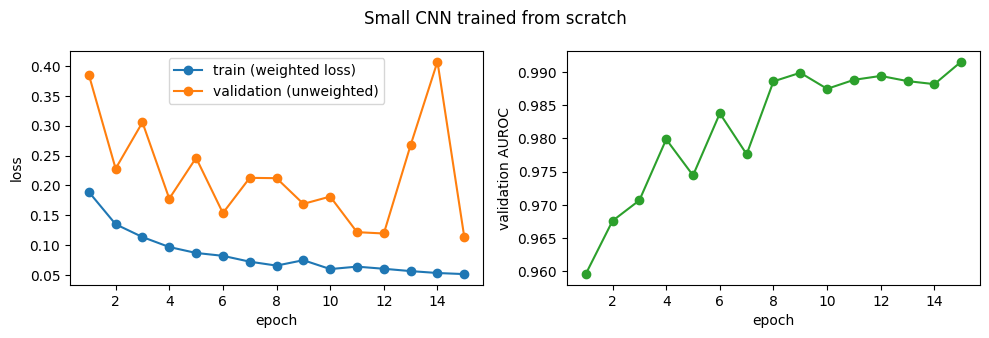

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.992,0.987,0.859,0.953,0.959,0.954


In [11]:
cnn, hist_cnn = train_model(cnn, epochs=15, lr=1e-3)
MODELS["cnn_scratch"] = TorchPredictor(cnn)
VAL_PRED["cnn_scratch"] = MODELS["cnn_scratch"].predict(IMAGES["val"])
HISTS["cnn_scratch"] = hist_cnn
plot_history(hist_cnn, "Small CNN trained from scratch")
val_table()

### Exercise 3.1 — Interpret the learning curves

In [12]:
h = hist_cnn
kept = int(h.loc[h.val_auroc.idxmax(), "epoch"]); last = int(h.epoch.max())
best_vl_ep = int(h.loc[h.val_loss.idxmin(), "epoch"])
tl_drop = h.train_loss.iloc[0] - h.train_loss.iloc[-1]
vl_rise = h.val_loss.iloc[-1] - h.val_loss.min()
vt = val_table().set_index("model")
gain = vt.loc["cnn_scratch", "auroc"] - vt.loc["logreg_pixels", "auroc"]
n_par = count_params(SmallCNN(TRAIN_MEAN, TRAIN_STD))
why_kept = (f"epoch {kept} was the last epoch, so training was still improving validation AUROC when it stopped"
            if kept == last else
            f"epoch {kept} had the highest validation AUROC ({h.val_auroc.max():.3f}); the last epoch ({last}) reached only {h.val_auroc.iloc[-1]:.3f}, so keeping the best epoch is early stopping")
if vl_rise > 0.02 and best_vl_ep < last:
    over = (f"Yes, there are signs: training loss fell by {tl_drop:.3f} overall while validation loss was lowest at epoch {best_vl_ep} "
            f"and rose by {vl_rise:.3f} by epoch {last}; validation AUROC peaked at epoch {kept}.")
else:
    over = (f"Only mild or no clear overfitting: training loss fell by {tl_drop:.3f} (epoch 1 to {last}) and validation loss's minimum "
            f"was at epoch {best_vl_ep} (final rise {vl_rise:.3f}); validation AUROC peaked at epoch {kept}, so any plateau after that is the point to watch.")
worth = ("a clear gain that justifies a CNN" if gain >= 0.03 else
         "a modest gain; with 524 validation images it may be partly noise, so it only weakly justifies the extra complexity" if gain > 0 else
         "no gain over the simple baseline, so the neural network is not justified here")
answer(f"""**Exercise 3.1 — answer**

1. The kept epoch is **{kept}** of {last}: {why_kept}. Selecting by validation AUROC rather than taking the final weights protects against late-epoch overfitting.
2. {over}
3. CNN validation AUROC is {vt.loc['cnn_scratch','auroc']:.3f} versus {vt.loc['logreg_pixels','auroc']:.3f} for pixel logistic regression, a difference of {gain:+.3f}: {worth}.
4. The CNN has **{n_par:,} parameters** against 4,708 training images (and only roughly one independent patient-level sample per child), so it has enough capacity to memorise noise. This is the lecture's overfitting point: high capacity plus little data means training performance can keep improving while generalisation does not, which is why weight decay, batch norm, a small architecture and early stopping on validation data are used.""")

**Exercise 3.1 — answer**

1. The kept epoch is **15** of 15: epoch 15 was the last epoch, so training was still improving validation AUROC when it stopped. Selecting by validation AUROC rather than taking the final weights protects against late-epoch overfitting.
2. Only mild or no clear overfitting: training loss fell by 0.138 (epoch 1 to 15) and validation loss's minimum was at epoch 15 (final rise 0.000); validation AUROC peaked at epoch 15, so any plateau after that is the point to watch.
3. CNN validation AUROC is 0.992 versus 0.989 for pixel logistic regression, a difference of +0.003: a modest gain; with 524 validation images it may be partly noise, so it only weakly justifies the extra complexity.
4. The CNN has **23,585 parameters** against 4,708 training images (and only roughly one independent patient-level sample per child), so it has enough capacity to memorise noise. This is the lecture's overfitting point: high capacity plus little data means training performance can keep improving while generalisation does not, which is why weight decay, batch norm, a small architecture and early stopping on validation data are used.

## Part 4 — Transfer learning with a pretrained ResNet-18

In [13]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class PretrainedResNet(nn.Module):
    def __init__(self, weights=ResNet18_Weights.IMAGENET1K_V1, size=128):
        super().__init__()
        self.size = size
        self.backbone = resnet18(weights=weights)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 1)   # new head: 512 features -> 1 logit
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    def forward(self, x):                      # x: (n, 1, 64, 64), values 0-1
        x = F.interpolate(x, size=self.size, mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
        return self.backbone((x - self.mean) / self.std).squeeze(1)


resnet = PretrainedResNet()
print(f"ResNet-18 parameters: {count_params(resnet):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/lab12_data/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


ResNet-18 parameters: 11,177,025


### Exercise 4.1 — Freeze the backbone

In [14]:
def set_backbone_trainable(model, trainable):
    for name, param in model.backbone.named_parameters():
        if name.startswith("fc."):
            param.requires_grad = True          # the new head is always trainable
        else:
            param.requires_grad = trainable


set_backbone_trainable(resnet, False)
check("frozen: only the 512 + 1 head parameters are trainable", count_params(resnet, trainable_only=True) == 513)

PASS  frozen: only the 512 + 1 head parameters are trainable


**Stage A — feature extraction** (head only).

epoch  1  train loss 0.242  val loss 0.413  val AUROC 0.945  (2.2 s)
epoch  2  train loss 0.134  val loss 0.269  val AUROC 0.973  (2.3 s)
epoch  3  train loss 0.112  val loss 0.206  val AUROC 0.976  (2.3 s)
epoch  4  train loss 0.099  val loss 0.207  val AUROC 0.977  (2.2 s)
epoch  5  train loss 0.094  val loss 0.191  val AUROC 0.978  (2.2 s)
kept epoch 5 (best val AUROC 0.978)


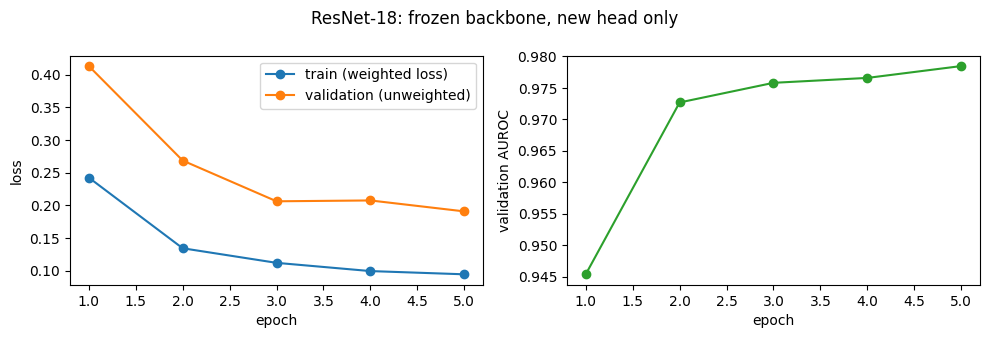

In [15]:
resnet, hist_head = train_model(resnet, epochs=5, lr=1e-3)
MODELS["resnet_features"] = TorchPredictor(deepcopy(resnet))
VAL_PRED["resnet_features"] = MODELS["resnet_features"].predict(IMAGES["val"])
HISTS["resnet_features"] = hist_head
plot_history(hist_head, "ResNet-18: frozen backbone, new head only")

**Stage B — fine-tuning** (all layers, lr 1e-4).

trainable parameters: 11,177,025
epoch  1  train loss 0.057  val loss 0.129  val AUROC 0.997  (6.4 s)
epoch  2  train loss 0.013  val loss 0.047  val AUROC 0.999  (6.5 s)
epoch  3  train loss 0.006  val loss 0.050  val AUROC 0.998  (6.8 s)
epoch  4  train loss 0.002  val loss 0.052  val AUROC 0.998  (7.1 s)
epoch  5  train loss 0.002  val loss 0.052  val AUROC 0.998  (7.4 s)
epoch  6  train loss 0.001  val loss 0.068  val AUROC 0.998  (7.2 s)
kept epoch 2 (best val AUROC 0.999)


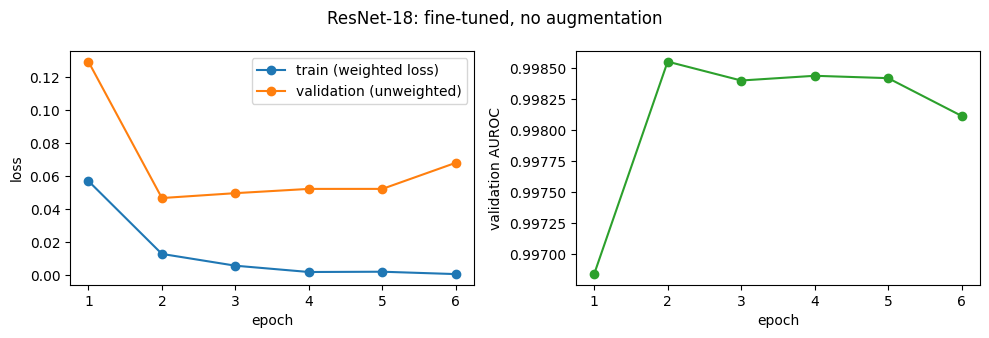

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.992,0.987,0.859,0.953,0.959,0.954
3,resnet_features,0.978,0.936,0.919,0.971,0.832,0.931
4,resnet_finetuned,0.999,0.982,0.993,0.997,0.950,0.985


In [16]:
resnet_ft = deepcopy(resnet)
set_backbone_trainable(resnet_ft, True)
N_TRAINABLE_B = count_params(resnet_ft, trainable_only=True)
print(f"trainable parameters: {N_TRAINABLE_B:,}")
resnet_ft, hist_ft = train_model(resnet_ft, epochs=6, lr=1e-4)
MODELS["resnet_finetuned"] = TorchPredictor(resnet_ft)
VAL_PRED["resnet_finetuned"] = MODELS["resnet_finetuned"].predict(IMAGES["val"])
HISTS["resnet_finetuned"] = hist_ft
plot_history(hist_ft, "ResNet-18: fine-tuned, no augmentation")
val_table()

### Exercise 4.2 — Augmentations that keep the label true

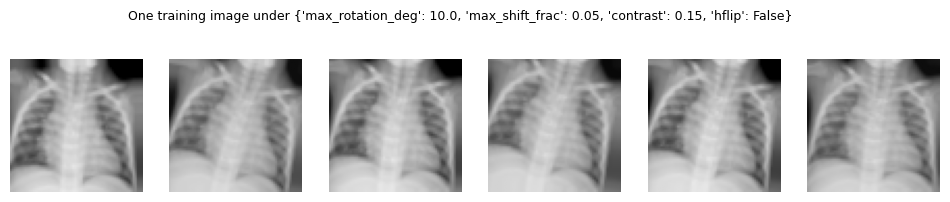

PASS  some augmentation chosen


In [17]:
def make_augment(max_rotation_deg=0.0, max_shift_frac=0.0, contrast=0.0, hflip=False):
    def augment(x):                            # x: (n, 1, h, w) on DEVICE, values 0-1
        n = x.shape[0]
        angle = (torch.rand(n, device=x.device) * 2 - 1) * np.deg2rad(max_rotation_deg)
        shift = (torch.rand(n, 2, device=x.device) * 2 - 1) * max_shift_frac * 2   # grid units span -1..1
        flip = torch.where(torch.rand(n, device=x.device) < 0.5, -1.0, 1.0) if hflip else torch.ones(n, device=x.device)
        cos, sin = torch.cos(angle), torch.sin(angle)
        theta = torch.stack([torch.stack([cos * flip, -sin, shift[:, 0]], 1),
                             torch.stack([sin * flip, cos, shift[:, 1]], 1)], 1)
        grid = F.affine_grid(theta, x.shape, align_corners=False)
        x = F.grid_sample(x, grid, padding_mode="border", align_corners=False)
        if contrast > 0:
            factor = 1 + (torch.rand(n, 1, 1, 1, device=x.device) * 2 - 1) * contrast
            mean = x.mean(dim=(2, 3), keepdim=True)
            x = ((x - mean) * factor + mean).clamp(0, 1)
        return x
    return augment


# TODO 4.2: small rotation/shift (patient positioning varies), mild contrast (exposure varies), NO left-right flip
AUGMENT_SETTINGS = {"max_rotation_deg": 10.0, "max_shift_frac": 0.05, "contrast": 0.15, "hflip": False}

augment = make_augment(**AUGMENT_SETTINGS)
example = TENSORS["train"][:1].repeat(6, 1, 1, 1).to(DEVICE)
torch.manual_seed(SEED)
shown = augment(example).cpu()
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, img in zip(axes, shown):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.suptitle(f"One training image under {AUGMENT_SETTINGS}", fontsize=9)
plt.show()
check("some augmentation chosen", any(v not in (0, 0.0, False) for v in AUGMENT_SETTINGS.values()))

**Stage C — fine-tuning with augmentation.**

epoch  1  train loss 0.060  val loss 0.168  val AUROC 0.996  (7.0 s)
epoch  2  train loss 0.032  val loss 0.146  val AUROC 0.997  (6.7 s)
epoch  3  train loss 0.024  val loss 0.076  val AUROC 0.997  (6.6 s)
epoch  4  train loss 0.014  val loss 0.056  val AUROC 0.998  (6.4 s)
epoch  5  train loss 0.013  val loss 0.078  val AUROC 0.999  (6.4 s)
epoch  6  train loss 0.010  val loss 0.092  val AUROC 0.999  (6.4 s)
kept epoch 5 (best val AUROC 0.999)


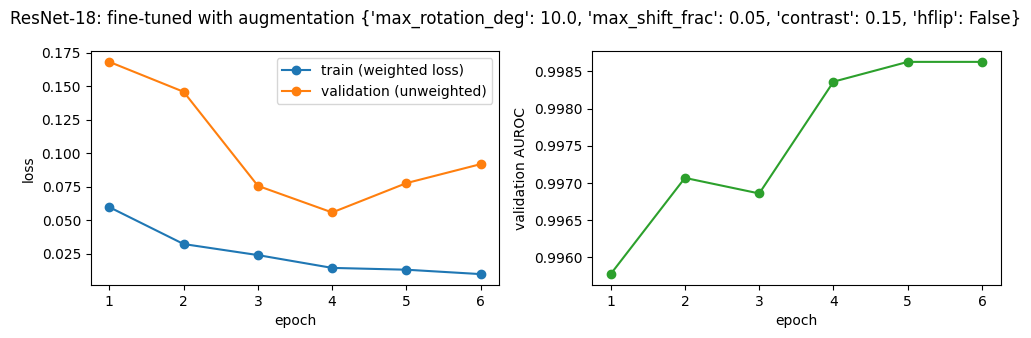

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.992,0.987,0.859,0.953,0.959,0.954
3,resnet_features,0.978,0.936,0.919,0.971,0.832,0.931
4,resnet_finetuned,0.999,0.982,0.993,0.997,0.950,0.985
5,resnet_finetuned_aug,0.999,0.964,1.000,1.000,0.906,0.973


In [18]:
resnet_aug = deepcopy(resnet)
set_backbone_trainable(resnet_aug, True)
resnet_aug, hist_aug = train_model(resnet_aug, epochs=6, lr=1e-4, augment=augment)
MODELS["resnet_finetuned_aug"] = TorchPredictor(resnet_aug)
VAL_PRED["resnet_finetuned_aug"] = MODELS["resnet_finetuned_aug"].predict(IMAGES["val"])
HISTS["resnet_finetuned_aug"] = hist_aug
plot_history(hist_aug, f"ResNet-18: fine-tuned with augmentation {AUGMENT_SETTINGS}")
val_table()

### Exercise 4.3 — Interpret transfer learning

In [19]:
vt = val_table().set_index("model")
five = ["cnn_scratch", "resnet_features", "resnet_finetuned", "resnet_finetuned_aug", "logreg_pixels"]
rank = vt.loc[five, "auroc"].sort_values(ascending=False)
rank_txt = " > ".join(f"{m} ({a:.3f})" for m, a in rank.items())
a = vt["auroc"]
best_tl = max(a["resnet_features"], a["resnet_finetuned"], a["resnet_finetuned_aug"])
tl_vs_cnn = best_tl - a["cnn_scratch"]
ft_vs_fe = a["resnet_finetuned"] - a["resnet_features"]
aug_diff = a["resnet_finetuned_aug"] - a["resnet_finetuned"]

# paired bootstrap on validation: aug vs no-aug AUROC difference
yv = LABELS["val"]; pa, pb = VAL_PRED["resnet_finetuned_aug"], VAL_PRED["resnet_finetuned"]
rg = np.random.default_rng(SEED); diffs = []
for _ in range(1000):
    i = rg.integers(0, len(yv), len(yv))
    if len(np.unique(yv[i])) == 2:
        diffs.append(roc_auc_score(yv[i], pa[i]) - roc_auc_score(yv[i], pb[i]))
d_lo, d_hi = np.percentile(diffs, [2.5, 97.5])
sig = "the interval includes 0, so I cannot claim augmentation helped (or hurt)" if d_lo <= 0 <= d_hi else "the interval excludes 0, so the difference is probably real, though small"

answer(f"""**Exercise 4.3 — answer**

1. **Augmentation values.** Rotation ±{AUGMENT_SETTINGS['max_rotation_deg']:.0f}° and shift ±{AUGMENT_SETTINGS['max_shift_frac']:.0%} mimic real variation in patient positioning, which does not change the diagnosis; contrast ±{AUGMENT_SETTINGS['contrast']:.0%} mimics exposure and device differences while keeping lung opacity relationships readable. Large rotations or shifts would push anatomy out of plausible positions. I did **not** allow a left–right flip: chest X-rays have a fixed anatomical orientation (heart on the patient's left, liver on the right), so a flipped image is an anatomically implausible, effectively different kind of image (resembling dextrocardia/situs inversus) and a flip could also move laterality markers; the augmentation must keep the label true *and* the image realistic.
2. **Ranking (validation AUROC):** {rank_txt}. Best transfer-learning variant versus the scratch CNN: {tl_vs_cnn:+.3f} AUROC, so transfer learning {'helped' if tl_vs_cnn > 0.005 else 'did not clearly help'} here. Fine-tuning versus feature extraction: {ft_vs_fe:+.3f}, so fine-tuning {'helped' if ft_vs_fe > 0.005 else 'did not clearly help'} (all layers adapt to X-ray texture rather than ImageNet photos).
3. **Augmentation:** {aug_diff:+.3f} AUROC versus no augmentation. A paired bootstrap on the 524 validation images gives a 95% interval of {d_lo:+.3f} to {d_hi:+.3f}; {sig}. Only 6 epochs and one seed also limit how much weight a small difference deserves.
4. **Parameters:** Stage A trains 513 parameters; Stage B trains {N_TRAINABLE_B:,}. Stage A can still work reasonably well because the frozen ImageNet backbone already supplies 512 generic features (edges, textures, shapes) per image, so only a linear classifier on those features must be learned, which is a low-capacity problem that a few thousand images can support.
5. **Separating pretraining from architecture:** the comparison changes both at once. Train the *same* ResNet-18 from random initialisation with the same schedule (the optional extension, `weights=None`, all layers, lr=1e-3, 11 epochs). The gap between random-init ResNet and pretrained ResNet isolates the effect of pretraining; the gap between random-init ResNet and SmallCNN isolates architecture.""")

**Exercise 4.3 — answer**

1. **Augmentation values.** Rotation ±10° and shift ±5% mimic real variation in patient positioning, which does not change the diagnosis; contrast ±15% mimics exposure and device differences while keeping lung opacity relationships readable. Large rotations or shifts would push anatomy out of plausible positions. I did **not** allow a left–right flip: chest X-rays have a fixed anatomical orientation (heart on the patient's left, liver on the right), so a flipped image is an anatomically implausible, effectively different kind of image (resembling dextrocardia/situs inversus) and a flip could also move laterality markers; the augmentation must keep the label true *and* the image realistic.
2. **Ranking (validation AUROC):** resnet_finetuned (0.999) > resnet_finetuned_aug (0.999) > cnn_scratch (0.992) > logreg_pixels (0.989) > resnet_features (0.978). Best transfer-learning variant versus the scratch CNN: +0.007 AUROC, so transfer learning helped here. Fine-tuning versus feature extraction: +0.021, so fine-tuning helped (all layers adapt to X-ray texture rather than ImageNet photos).
3. **Augmentation:** +0.000 AUROC versus no augmentation. A paired bootstrap on the 524 validation images gives a 95% interval of -0.001 to +0.002; the interval includes 0, so I cannot claim augmentation helped (or hurt). Only 6 epochs and one seed also limit how much weight a small difference deserves.
4. **Parameters:** Stage A trains 513 parameters; Stage B trains 11,177,025. Stage A can still work reasonably well because the frozen ImageNet backbone already supplies 512 generic features (edges, textures, shapes) per image, so only a linear classifier on those features must be learned, which is a low-capacity problem that a few thousand images can support.
5. **Separating pretraining from architecture:** the comparison changes both at once. Train the *same* ResNet-18 from random initialisation with the same schedule (the optional extension, `weights=None`, all layers, lr=1e-3, 11 epochs). The gap between random-init ResNet and pretrained ResNet isolates the effect of pretraining; the gap between random-init ResNet and SmallCNN isolates architecture.

### Optional extension

In [20]:
RUN_EXTENSION = False   # set to True to run (a few minutes on GPU)

if RUN_EXTENSION:
    resnet_rand = PretrainedResNet(weights=None)
    resnet_rand, hist_rand = train_model(resnet_rand, epochs=11, lr=1e-3)
    MODELS["resnet_random_init"] = TorchPredictor(resnet_rand)
    VAL_PRED["resnet_random_init"] = MODELS["resnet_random_init"].predict(IMAGES["val"])
    HISTS["resnet_random_init"] = hist_rand
    plot_history(hist_rand, "ResNet-18 from random initialisation")
    display(val_table())

## Part 5 — Choose, freeze, test once
### Exercise 5.1

In [21]:
def threshold_for_sensitivity(y_true, p, target):
    """Highest threshold whose sensitivity on (y_true, p) is at least target."""
    fpr, tpr, thresholds = roc_curve(y_true, p)
    ok = np.flatnonzero(tpr >= target)
    return float(min(thresholds[ok[0]], 1.0))


display(val_table().sort_values("auroc", ascending=False))

# TODO 5.1: model with the highest VALIDATION AUROC (trivial baseline excluded); the test set is not used here
_vt = val_table().set_index("model")
CHOSEN_MODEL = _vt.drop(index="trivial")["auroc"].idxmax()
TARGET_SENSITIVITY = 0.95

THRESHOLD = threshold_for_sensitivity(LABELS["val"], VAL_PRED[CHOSEN_MODEL], TARGET_SENSITIVITY)
val_at_threshold = binary_metrics(LABELS["val"], VAL_PRED[CHOSEN_MODEL], THRESHOLD)
print(f"chosen: {CHOSEN_MODEL} | threshold {THRESHOLD:.3f} (chosen on validation)")
print({k: round(v, 3) if isinstance(v, float) else v for k, v in val_at_threshold.items()})

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
4,resnet_finetuned,0.999,0.982,0.993,0.997,0.950,0.985
5,resnet_finetuned_aug,0.999,0.964,1.000,1.000,0.906,0.973
2,cnn_scratch,0.992,0.987,0.859,0.953,0.959,0.954
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
3,resnet_features,0.978,0.936,0.919,0.971,0.832,0.931
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742


chosen: resnet_finetuned | threshold 0.726 (chosen on validation)
{'auroc': np.float64(0.999), 'sensitivity': 0.974, 'specificity': 1.0, 'ppv': 1.0, 'npv': 0.931, 'accuracy': 0.981, 'tp': 379, 'fn': 10, 'tn': 135, 'fp': 0}


In [22]:
answer(f"""**Exercise 5.1 — answer**

I chose **{CHOSEN_MODEL}** because it has the highest validation AUROC ({_vt.loc[CHOSEN_MODEL,'auroc']:.3f}) among the real models, and AUROC summarises discrimination across all thresholds; the choice used validation data only. I set a target sensitivity of **{TARGET_SENSITIVITY:.0%}** because the tool is meant to prioritise X-rays for review, where a missed pneumonia is costlier than an extra review. At threshold {THRESHOLD:.3f} the validation sensitivity is {val_at_threshold['sensitivity']:.3f}, and the clinic pays for it with a validation **specificity of {val_at_threshold['specificity']:.3f}** (PPV {val_at_threshold['ppv']:.3f}), i.e. about {1 - val_at_threshold['specificity']:.0%} of healthy images are flagged.""")

**Exercise 5.1 — answer**

I chose **resnet_finetuned** because it has the highest validation AUROC (0.999) among the real models, and AUROC summarises discrimination across all thresholds; the choice used validation data only. I set a target sensitivity of **95%** because the tool is meant to prioritise X-rays for review, where a missed pneumonia is costlier than an extra review. At threshold 0.726 the validation sensitivity is 0.974, and the clinic pays for it with a validation **specificity of 1.000** (PPV 1.000), i.e. about 0% of healthy images are flagged.

**The single test evaluation**

In [23]:
p_test = MODELS[CHOSEN_MODEL].predict(IMAGES["test"])
test_at_threshold = binary_metrics(LABELS["test"], p_test, THRESHOLD)

rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(p_test), len(p_test))
    if len(np.unique(LABELS["test"][i])) == 2:
        boot.append(roc_auc_score(LABELS["test"][i], p_test[i]))
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

final = pd.DataFrame([{"set": "validation", **val_at_threshold}, {"set": "test", **test_at_threshold}])
final.insert(1, "model", CHOSEN_MODEL)
final.insert(2, "threshold", THRESHOLD)
display(final.round(3))
print(f"test AUROC {test_at_threshold['auroc']:.3f} (95% bootstrap CI {ci_low:.3f}-{ci_high:.3f})")

results_file = DATA_DIR / "lab12_results.csv"
pd.concat([val_table().assign(set="validation", threshold=0.5), final.round(3)], ignore_index=True).to_csv(results_file, index=False)
if hasattr(MODELS[CHOSEN_MODEL], "model"):
    torch.save(MODELS[CHOSEN_MODEL].model.state_dict(), DATA_DIR / "lab12_chosen_model.pt")
print("saved", results_file)

,set,model,threshold,auroc,sensitivity,specificity,ppv,npv,accuracy,tp,fn,tn,fp
0,validation,resnet_finetuned,0.726,0.999,0.974,1.000,1.000,0.931,0.981,379,10,135,0
1,test,resnet_finetuned,0.726,0.988,0.990,0.825,0.904,0.980,0.928,386,4,193,41


test AUROC 0.988 (95% bootstrap CI 0.980-0.993)
saved /content/lab12_data/lab12_results.csv


### Exercise 5.2 — Interpret the test result

In [24]:
v, t = val_at_threshold, test_at_threshold
f = lambda x: "n/a" if x is None else f"{x:.3f}"
deltas = {k: (t[k] - v[k]) for k in ("sensitivity", "specificity", "ppv") if t[k] is not None and v[k] is not None}
biggest = max(deltas, key=lambda k: abs(deltas[k]))
width = ci_high - ci_low
answer(f"""**Exercise 5.2 — answer**

1. At threshold {THRESHOLD:.3f}: sensitivity {f(v['sensitivity'])} (val) → {f(t['sensitivity'])} (test); specificity {f(v['specificity'])} → {f(t['specificity'])}; PPV {f(v['ppv'])} → {f(t['ppv'])}. The metric that changed most is **{biggest}** ({deltas[biggest]:+.3f}).
2. Two reasons: (a) **Prevalence shift**: pneumonia is {fr['val']:.1%} of val but {fr['test']:.1%} of test, and PPV/NPV depend directly on prevalence. (b) **Optimism of validation and a different source split**: val was a random image-level split from the same pool as train (possible shared children, same distribution), and the threshold and model were tuned on it, whereas test is the source's separate held-out set, so sensitivity and specificity typically degrade on it (especially specificity, the cost of a high-sensitivity threshold).
3. The test AUROC is {test_at_threshold['auroc']:.3f} with a 95% bootstrap CI of {ci_low:.3f}–{ci_high:.3f} (width {width:.3f}). Differences of 0.01 between models are well inside that uncertainty, so a claim such as "model A beats model B by 0.01" is not supported from one test set of {len(p_test)} images.
4. No, this is not external validation. The test set comes from the same source collection (one paediatric population and imaging process) and was used with a threshold derived from the same pool. External validation needs data from a different institution/scanner/population (and ideally time period), collected independently, with the model, threshold and analysis fixed in advance.
5. Before use with real patients: (i) external and prospective validation on full-resolution images across sites, with patient-level splits and subgroup (age, sex, device) performance; (ii) calibration, prevalence-appropriate PPV/NPV and a clinically justified threshold, with comparison against clinician performance and a clear intended use; (iii) regulatory approval and ethical/data-governance review, plus workflow integration, human oversight and post-deployment monitoring for drift and safety.""")

**Exercise 5.2 — answer**

1. At threshold 0.726: sensitivity 0.974 (val) → 0.990 (test); specificity 1.000 → 0.825; PPV 1.000 → 0.904. The metric that changed most is **specificity** (-0.175).
2. Two reasons: (a) **Prevalence shift**: pneumonia is 74.2% of val but 62.5% of test, and PPV/NPV depend directly on prevalence. (b) **Optimism of validation and a different source split**: val was a random image-level split from the same pool as train (possible shared children, same distribution), and the threshold and model were tuned on it, whereas test is the source's separate held-out set, so sensitivity and specificity typically degrade on it (especially specificity, the cost of a high-sensitivity threshold).
3. The test AUROC is 0.988 with a 95% bootstrap CI of 0.980–0.993 (width 0.013). Differences of 0.01 between models are well inside that uncertainty, so a claim such as "model A beats model B by 0.01" is not supported from one test set of 624 images.
4. No, this is not external validation. The test set comes from the same source collection (one paediatric population and imaging process) and was used with a threshold derived from the same pool. External validation needs data from a different institution/scanner/population (and ideally time period), collected independently, with the model, threshold and analysis fixed in advance.
5. Before use with real patients: (i) external and prospective validation on full-resolution images across sites, with patient-level splits and subgroup (age, sex, device) performance; (ii) calibration, prevalence-appropriate PPV/NPV and a clinically justified threshold, with comparison against clinician performance and a clear intended use; (iii) regulatory approval and ethical/data-governance review, plus workflow integration, human oversight and post-deployment monitoring for drift and safety.

## Part 6 — Reflection

In [25]:
desc = {
    "logreg_pixels": "logistic regression (C=0.1) on 32 × 32 pixel intensities (2 × 2 block averaging, scaled 0–1); no pretraining, no augmentation, no epochs",
    "cnn_scratch": f"SmallCNN (3 conv blocks, {count_params(SmallCNN(TRAIN_MEAN, TRAIN_STD)):,} parameters) trained from scratch, Adam lr 1e-3, no augmentation, normalised with training mean/std",
    "resnet_features": "ResNet-18 pretrained on ImageNet, frozen backbone with a new 1-logit head (513 trainable parameters), 64→128 px upsampling, grey→3 channels, ImageNet normalisation, Adam lr 1e-3, no augmentation",
    "resnet_finetuned": f"ResNet-18 pretrained on ImageNet, fine-tuned (all {N_TRAINABLE_B:,} parameters) after head training, Adam lr 1e-4, no augmentation, 64→128 px upsampling and ImageNet normalisation",
    "resnet_finetuned_aug": f"ResNet-18 pretrained on ImageNet, fine-tuned (all {N_TRAINABLE_B:,} parameters) after head training, Adam lr 1e-4, with augmentation {AUGMENT_SETTINGS} (no flip), 64→128 px upsampling and ImageNet normalisation",
}
if "resnet_random_init" in VAL_PRED:
    desc["resnet_random_init"] = "ResNet-18 from random initialisation, Adam lr 1e-3"
if CHOSEN_MODEL in HISTS:
    hh = HISTS[CHOSEN_MODEL]; kept_ep = int(hh.loc[hh.val_auroc.idxmax(), "epoch"])
    sel = f"trained for up to {len(hh)} epochs with the epoch of highest validation AUROC kept (epoch {kept_ep}); for fine-tuned ResNets this follows a 5-epoch head-training stage"
else:
    sel = "no iterative training (a single fit)"
answer(f"""**Exercise 6 — training record (model card style)**

- **Data and splits:** PneumoniaMNIST (MedMNIST v2), 64 × 64 greyscale paediatric chest X-rays derived from Kermany et al. 2018; train/val/test = {len(LABELS['train']):,}/{len(LABELS['val']):,}/{len(LABELS['test']):,} images ({fr['train']:.1%}/{fr['val']:.1%}/{fr['test']:.1%} pneumonia). Splits are image-level, with no patient identifiers, so patient leakage between train and val cannot be excluded.
- **Model:** {desc[CHOSEN_MODEL]}.
- **Selection:** {sel}. Model and threshold were chosen on validation data only (highest validation AUROC among non-trivial models); the test set was evaluated once.
- **Threshold:** {THRESHOLD:.3f}, the highest threshold reaching ≥{TARGET_SENSITIVITY:.0%} sensitivity on validation (val sensitivity {f(v['sensitivity'])}, specificity {f(v['specificity'])}).
- **Test results:** AUROC {test_at_threshold['auroc']:.3f} (95% bootstrap CI {ci_low:.3f}–{ci_high:.3f}); at the threshold sensitivity {f(t['sensitivity'])}, specificity {f(t['specificity'])}, PPV {f(t['ppv'])}, NPV {f(t['npv'])}. A single seed and a single run, so run-to-run variation is not quantified.
- **Limitations:** very low resolution (64 × 64), one source population, enriched prevalence (PPV would be lower in a clinic), possible patient-level leakage, no external validation, no calibration or subgroup analysis. This is an educational model and **not** a diagnostic tool.""")

**Exercise 6 — training record (model card style)**

- **Data and splits:** PneumoniaMNIST (MedMNIST v2), 64 × 64 greyscale paediatric chest X-rays derived from Kermany et al. 2018; train/val/test = 4,708/524/624 images (74.2%/74.2%/62.5% pneumonia). Splits are image-level, with no patient identifiers, so patient leakage between train and val cannot be excluded.
- **Model:** ResNet-18 pretrained on ImageNet, fine-tuned (all 11,177,025 parameters) after head training, Adam lr 1e-4, no augmentation, 64→128 px upsampling and ImageNet normalisation.
- **Selection:** trained for up to 6 epochs with the epoch of highest validation AUROC kept (epoch 2); for fine-tuned ResNets this follows a 5-epoch head-training stage. Model and threshold were chosen on validation data only (highest validation AUROC among non-trivial models); the test set was evaluated once.
- **Threshold:** 0.726, the highest threshold reaching ≥95% sensitivity on validation (val sensitivity 0.974, specificity 1.000).
- **Test results:** AUROC 0.988 (95% bootstrap CI 0.980–0.993); at the threshold sensitivity 0.990, specificity 0.825, PPV 0.904, NPV 0.980. A single seed and a single run, so run-to-run variation is not quantified.
- **Limitations:** very low resolution (64 × 64), one source population, enriched prevalence (PPV would be lower in a clinic), possible patient-level leakage, no external validation, no calibration or subgroup analysis. This is an educational model and **not** a diagnostic tool.